# Toronto Fleet — Unscheduled Repair Prediction: Exploratory Data Analysis

This notebook explores the three datasets provided by the City of Toronto Fleet Services
Division in preparation for a 7-day prediction of unscheduled repair events.

The three sources are `Driving Events.xlsx` (per speeding incident, with duration, distance,
and max speed vs the posted limit), `Engine Device Fault Alerts.xlsx` (per fault event, with
description, severity, source and DTC), and `Job History.xlsx` (per job line within a work
order, with description, reason code, and open / complete dates).

A conservative approach would restrict EDA to the training window only, so that no feature
engineering decision is accidentally informed by future data. For this assessment, since the
explicit instruction was to *"conduct an exploratory data analysis on the datasets provided"*,
I did EDA on the entire year to give a complete picture of fleet behaviour. Label leakage at
the modelling stage is instead handled by walk-forward cross-validation in `src/modeling.py`,
which guarantees the model itself never sees future information regardless of what the
analyst saw during exploration.

In [114]:
from pathlib import Path
import sys

# Make project root importable when the notebook is launched from notebooks/.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib_venn import venn3

from config import (
    FIGURES_DIR,
    MODEL_START_DATE,
    MODEL_END_DATE,
    UNSCHEDULED_REASONS,
    SCHEDULED_REASONS,
    EXCLUDED_REASONS,
)
from src import data_loading as dl
from src import data_cleaning as dc
from src.plotting import setup_style, save_fig, horizontal_bar, PALETTE

setup_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

## Dataset overview

In [115]:
frames = dl.load_all()
drives = frames["driving_events"]
faults = frames["faults"]
jobs = frames["jobs"]

dl.summarize([
    ("driving_events", drives),
    ("faults", faults),
    ("jobs", jobs),
])

,dataset,rows,unique_vehicles,date_min,date_max
0,driving_events,43118,598,2025-01-01 00:00:15.430,2025-12-30 23:52:48.090
1,faults,188022,245,2025-01-01 00:37:09.663,2025-12-31 23:27:18.000
2,jobs,36829,734,2024-05-29 13:18:43.000,2026-02-02 06:05:08.000


Faults and driving events cover all of calendar year 2025. Job history is wider on both ends,
from May 2024 to February 2026. A fair modelling window has to restrict to dates where all
three signals exist, which means 2025 (configured as `MODEL_START_DATE` / `MODEL_END_DATE` in
`config.py`). Faults are by far the largest table at ~188k rows.

### Vehicle ID normalisation

The raw files store `VEHICLE` with different dtypes. `Driving Events` and `Job History` use
`int64` (e.g. `158063`); `Engine Device Fault Alerts` uses zero-padded strings (e.g.
`"050296"`). All IDs are six characters wide, so `src.data_loading._normalize_vehicle_id`
converts everything to a zero-padded-string representation. Without this step, every
cross-dataset join would silently miss vehicles whose IDs begin with `0`.

In [116]:
for name, df in [("drives", drives), ("faults", faults), ("jobs", jobs)]:
    sample = sorted(df["VEHICLE"].unique())[:3]
    print(f"{name:7s}  dtype={df['VEHICLE'].dtype}  examples={sample}")

drives   dtype=string  examples=['050296', '135115', '135156']
faults   dtype=string  examples=['050296', '135115', '135156']
jobs     dtype=string  examples=['135115', '135156', '135157']


## Vehicle coverage across datasets

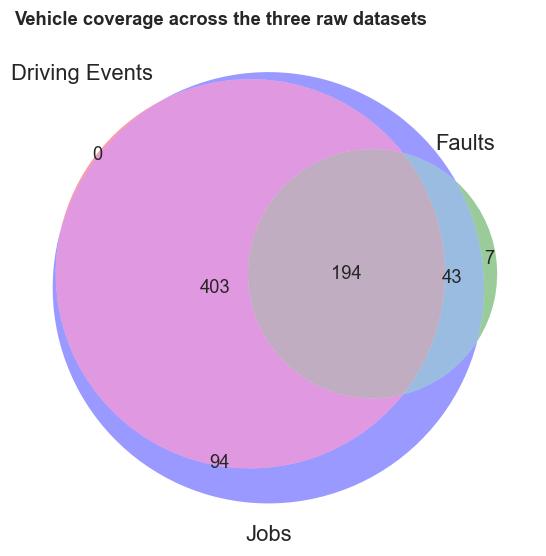

In [117]:
sets = dl.vehicle_sets(frames)

fig, ax = plt.subplots(figsize=(7, 6))
venn3(
    [sets["driving_events"], sets["faults"], sets["jobs"]],
    set_labels=("Driving Events", "Faults", "Jobs"),
    ax=ax,
)
ax.set_title("Vehicle coverage across the three raw datasets")
save_fig(fig, "01_vehicle_venn")
plt.show()

In [118]:
common = sets["driving_events"] & sets["faults"] & sets["jobs"]
print(f"Vehicles in all three datasets: {len(common):,}")
print(f"Total unique vehicles across datasets: {len(sets['driving_events'] | sets['faults'] | sets['jobs']):,}")

Vehicles in all three datasets: 194
Total unique vehicles across datasets: 742


The model is trained on vehicles that appear in all three datasets, since features from
every signal have to be available. Vehicles in only the Job History table likely represent
units that pre-date or post-date the telematics rollout window.

## Driving Events

### Events over time and per vehicle

Two side-by-side views. On the left, the weekly count of speeding incidents fleet-wide. On
the right, the distribution of per-vehicle incident counts, with the median and the 90th
percentile marked because the distribution is expected to be heavy-tailed.

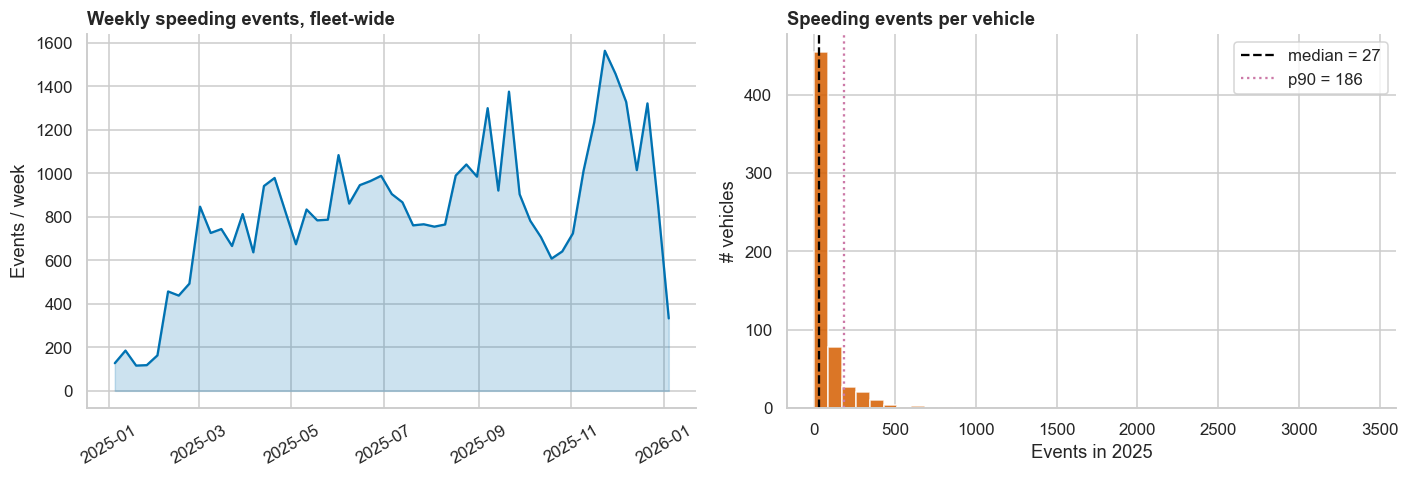

In [119]:
weekly = drives.set_index("DATETIME_START").resample("W")["VEHICLE"].count()
per_vehicle = drives.groupby("VEHICLE").size()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(weekly.index, weekly.values, color=PALETTE[0])
axes[0].fill_between(weekly.index, weekly.values, alpha=0.2, color=PALETTE[0])
axes[0].set_title("Weekly speeding events, fleet-wide")
axes[0].set_ylabel("Events / week")
axes[0].tick_params(axis="x", rotation=30)

axes[1].hist(per_vehicle, bins=40, color=PALETTE[1], alpha=0.85)
axes[1].axvline(per_vehicle.median(), color="black", linestyle="--", label=f"median = {per_vehicle.median():.0f}")
axes[1].axvline(per_vehicle.quantile(0.9), color=PALETTE[3], linestyle=":", label=f"p90 = {per_vehicle.quantile(0.9):.0f}")
axes[1].set_title("Speeding events per vehicle")
axes[1].set_xlabel("Events in 2025")
axes[1].set_ylabel("# vehicles")
axes[1].legend()
fig.tight_layout()
save_fig(fig, "02_drives_volume")
plt.show()

### Parsing the EXTRA_INFO column

`EXTRA_INFO` is a free-text field that always looks like it follows a consistent template,
but has at least three observed shapes:

```
(Max Speed: 70 km/h (Max road speed: 50 km/h, Max truck road speed: 50 km/h))
(Max Speed: 68 km/h (Max road speed: 50 km/h))
(Max Speed: 63 km/h (Max road speed: 50 km/h, estimate))
```

Rather than assume only those three forms exist, I collapse every string to a template
(digits become `#`) and count templates. That surfaces any unexpected formats before shipping
a parser to production.

In [120]:
templates = drives["EXTRA_INFO"].map(dc.extra_info_template).value_counts()
print(f"# distinct EXTRA_INFO templates: {len(templates)}")
templates.head(10).to_frame("count")

# distinct EXTRA_INFO templates: 3


,count
EXTRA_INFO,
(Max Speed: # km/h (Max road speed: # km/h)),41346
"(Max Speed: # km/h (Max road speed: # km/h, Max truck road speed: # km/h))",1081
"(Max Speed: # km/h (Max road speed: # km/h, estimate))",691


In [121]:
parsed = dc.parse_extra_info(drives["EXTRA_INFO"])
drives_parsed = pd.concat([drives, parsed], axis=1)

print("Parse coverage (non-null after parsing):")
print(parsed[["max_speed_kmh", "max_road_speed_kmh", "max_truck_road_speed_kmh", "is_estimate"]].notna().mean().round(3).to_string())

examples = dc.unparsed_extra_info_examples(drives, n=5)
if len(examples):
    print("\nUnparsed examples:")
    for e in examples:
        print(" -", e)
else:
    print("\nAll rows successfully parsed.")

Parse coverage (non-null after parsing):
max_speed_kmh               1.000
max_road_speed_kmh          1.000
max_truck_road_speed_kmh    0.025
is_estimate                 1.000

All rows successfully parsed.


### Speed-over-limit, duration, and distance

Three views in one row. Left: the speed over posted limit, clipped at the 99th percentile.
Middle: duration of each incident in seconds, log-scaled. Right: distance travelled during
the incident, also log-scaled.

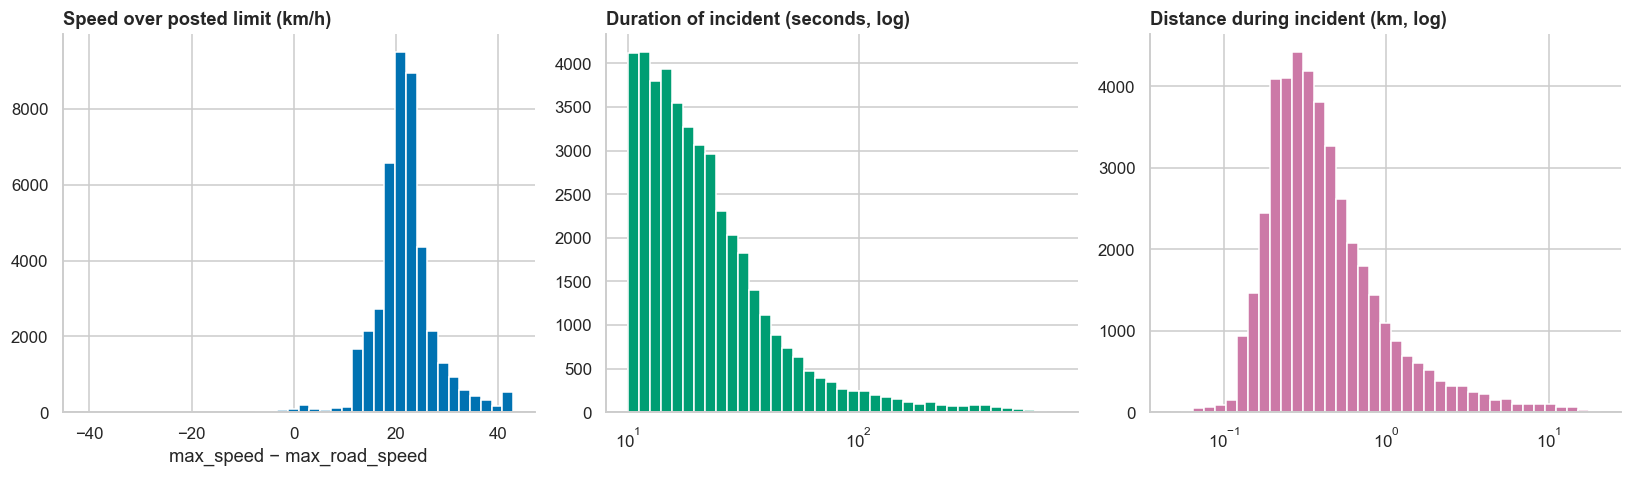

In [122]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

over = drives_parsed["speed_over_limit_kmh"].dropna()
cutoff = over.quantile(0.99)
axes[0].hist(over.clip(upper=cutoff), bins=40, color=PALETTE[0])
axes[0].set_title("Speed over posted limit (km/h)")
axes[0].set_xlabel("max_speed − max_road_speed")

dur = drives_parsed["DURATION_SECONDS"].clip(lower=0.1)
axes[1].hist(dur, bins=np.logspace(np.log10(dur.min()), np.log10(dur.max()), 40), color=PALETTE[2])
axes[1].set_xscale("log")
axes[1].set_title("Duration of incident (seconds, log)")

dist = drives_parsed["DISTANCE"].clip(lower=0.001)
axes[2].hist(dist, bins=np.logspace(np.log10(dist.min()), np.log10(dist.max()), 40), color=PALETTE[3])
axes[2].set_xscale("log")
axes[2].set_title("Distance during incident (km, log)")

fig.tight_layout()
save_fig(fig, "03_drives_distributions")
plt.show()

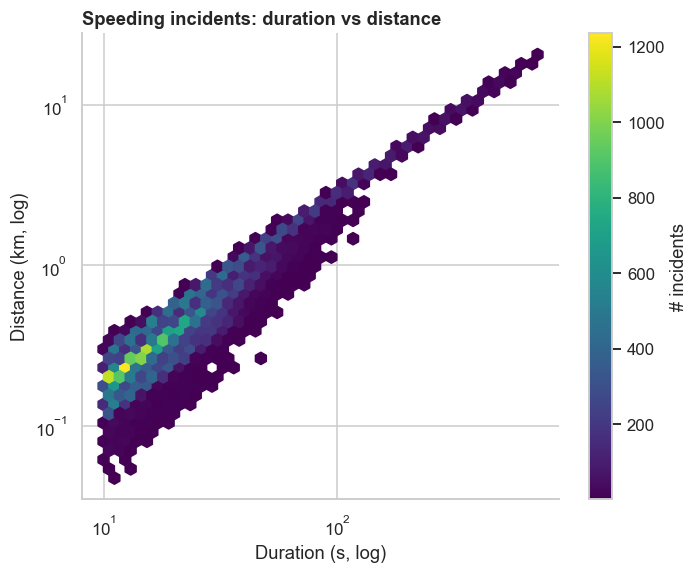

In [123]:
fig, ax = plt.subplots(figsize=(7, 5.5))
hb = ax.hexbin(
    drives_parsed["DURATION_SECONDS"].clip(lower=0.1),
    drives_parsed["DISTANCE"].clip(lower=0.001),
    gridsize=40,
    xscale="log",
    yscale="log",
    cmap="viridis",
    mincnt=1,
)
fig.colorbar(hb, ax=ax, label="# incidents")
ax.set_xlabel("Duration (s, log)")
ax.set_ylabel("Distance (km, log)")
ax.set_title("Speeding incidents: duration vs distance")
save_fig(fig, "04_drives_duration_distance_hex")
plt.show()

## Engine Device Fault Alerts

### Volume over time and per vehicle

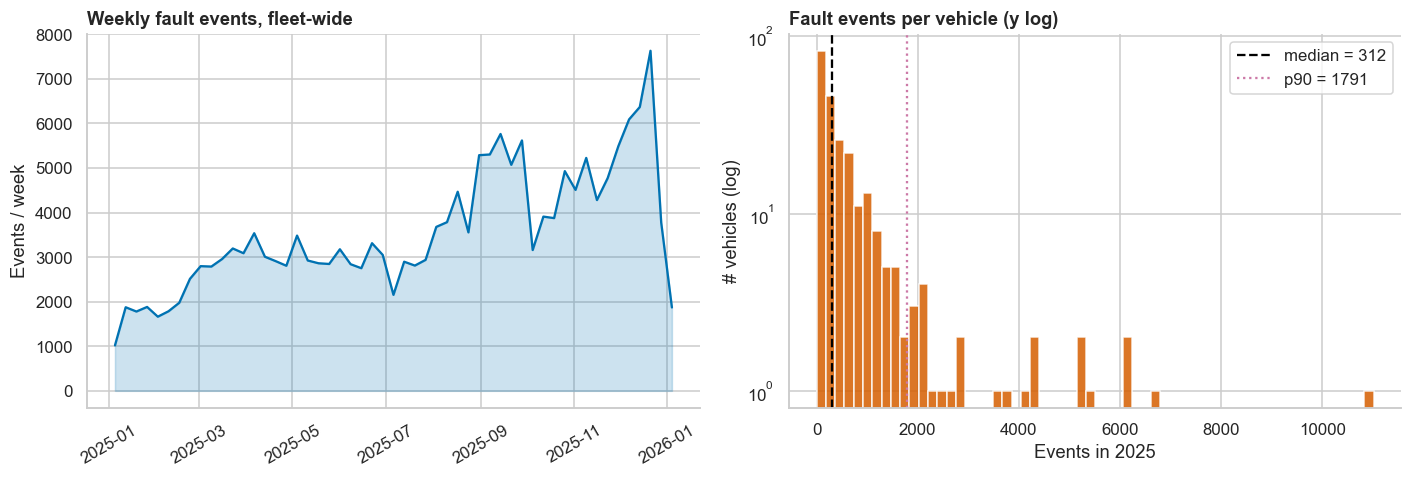

In [124]:
weekly_faults = faults.set_index("DATE_TIME").resample("W")["VEHICLE"].count()
per_vehicle_faults = faults.groupby("VEHICLE").size()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(weekly_faults.index, weekly_faults.values, color=PALETTE[0])
axes[0].fill_between(weekly_faults.index, weekly_faults.values, alpha=0.2, color=PALETTE[0])
axes[0].set_title("Weekly fault events, fleet-wide")
axes[0].set_ylabel("Events / week")
axes[0].tick_params(axis="x", rotation=30)

axes[1].hist(per_vehicle_faults, bins=60, color=PALETTE[1], alpha=0.85)
axes[1].axvline(per_vehicle_faults.median(), color="black", linestyle="--", label=f"median = {per_vehicle_faults.median():.0f}")
axes[1].axvline(per_vehicle_faults.quantile(0.9), color=PALETTE[3], linestyle=":", label=f"p90 = {per_vehicle_faults.quantile(0.9):.0f}")
axes[1].set_yscale("log")
axes[1].set_title("Fault events per vehicle (y log)")
axes[1].set_xlabel("Events in 2025")
axes[1].set_ylabel("# vehicles (log)")
axes[1].legend()
fig.tight_layout()
save_fig(fig, "05_faults_volume")
plt.show()

### Does FAULT_DESCRIPTION map one-to-one to CODE?

Worth confirming before treating either field as a clean categorical for modelling.

In [125]:
desc_to_codes = faults.groupby("FAULT_DESCRIPTION")["CODE"].nunique()
code_to_descs = faults.groupby("CODE")["FAULT_DESCRIPTION"].nunique()

print(f"# unique FAULT_DESCRIPTION values: {desc_to_codes.size:,}")
print(f"# unique CODE values:              {code_to_descs.size:,}")
print()
print(f"Descriptions associated with >1 code: {(desc_to_codes > 1).sum()}")
print(f"Codes associated with >1 description: {(code_to_descs > 1).sum()}")
print()
print("Top descriptions associated with multiple codes (if any):")
desc_to_codes[desc_to_codes > 1].sort_values(ascending=False).head(10)

# unique FAULT_DESCRIPTION values: 473
# unique CODE values:              461

Descriptions associated with >1 code: 3
Codes associated with >1 description: 13

Top descriptions associated with multiple codes (if any):


FAULT_DESCRIPTION
Controller #1                                                                                                      2
Engine oil change interval                                                                                         2
Telematics device fault: Low voltage power supply (bad battery or reinstallation required) and device restarted    2
Name: CODE, dtype: int64

### Top fault descriptions

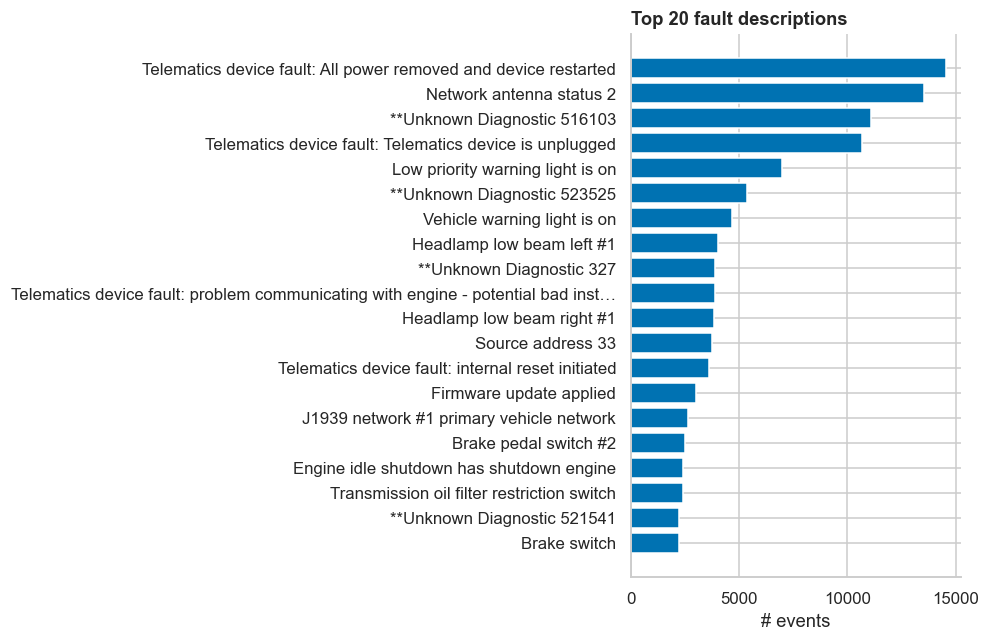

In [126]:
top_desc = faults["FAULT_DESCRIPTION"].value_counts().head(20)
fig = horizontal_bar(top_desc, title="Top 20 fault descriptions", xlabel="# events", top_n=None)
save_fig(fig, "06_faults_top_descriptions")
plt.show()

### Severity, failure mode, and source

`FAULT_SEVERITY` is null for roughly 55% of rows. The nulls come from rows where the source
is the telematics device itself rather than the engine. I treat them as a separate `Unrated`
category rather than imputing. `FAILURE_MODE` shows up as the string `"0"` on the same
telematics-device rows; the loader converts it to NaN. `SOURCE` has only four distinct
values, dominated by J1939 (the heavy-duty engine bus).

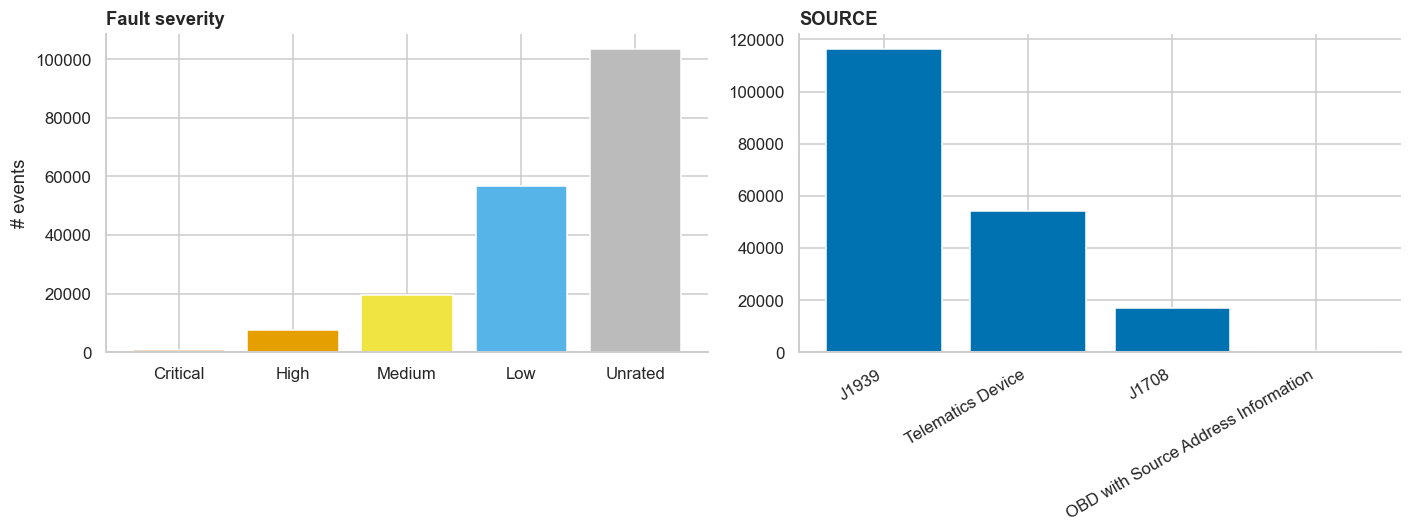

In [127]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sev_order = ["Critical", "High", "Medium", "Low", "Unrated"]
sev_counts = faults["FAULT_SEVERITY_FILLED"].value_counts().reindex(sev_order).fillna(0)
axes[0].bar(sev_counts.index, sev_counts.values, color=[PALETTE[1], PALETTE[6], PALETTE[4], PALETTE[5], "#BBBBBB"])
axes[0].set_title("Fault severity")
axes[0].set_ylabel("# events")

src_counts = faults["SOURCE"].value_counts()
axes[1].bar(src_counts.index, src_counts.values, color=PALETTE[0])
axes[1].set_title("SOURCE")
axes[1].set_xticks(range(len(src_counts)))
axes[1].set_xticklabels(src_counts.index, rotation=30, ha="right")

fig.tight_layout()
save_fig(fig, "07_faults_severity_source")
plt.show()

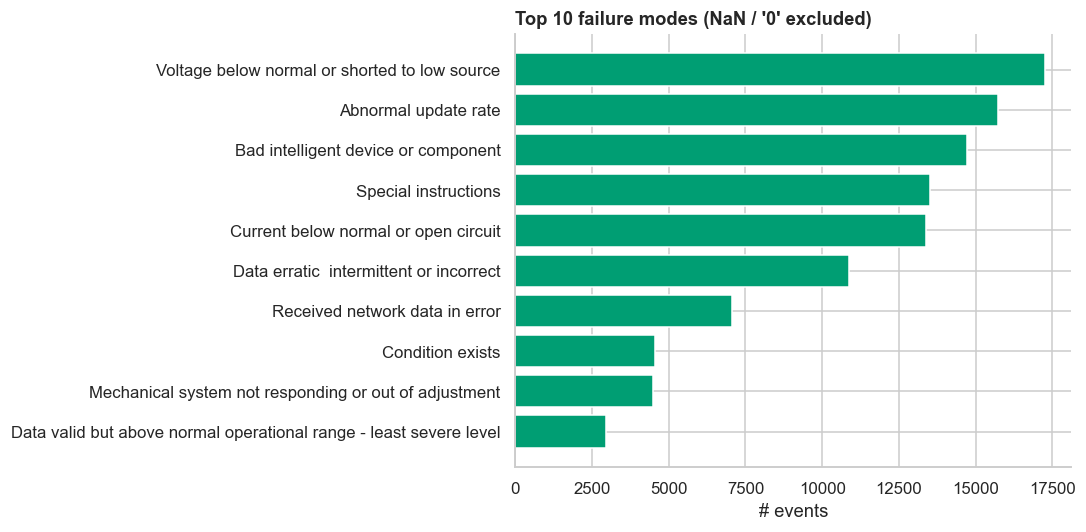

In [128]:
fm_counts = faults["FAILURE_MODE"].dropna().value_counts().head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(fm_counts.index, fm_counts.values, color=PALETTE[2])
ax.set_title("Top 10 failure modes (NaN / '0' excluded)")
ax.set_xlabel("# events")
fig.tight_layout()
save_fig(fig, "07b_faults_failure_modes")
plt.show()

### Weekly fault volume by severity

Putting severity and time on the same chart shows whether different severities track each
other or whether a wave of, say, Critical events ever rolls through the fleet.

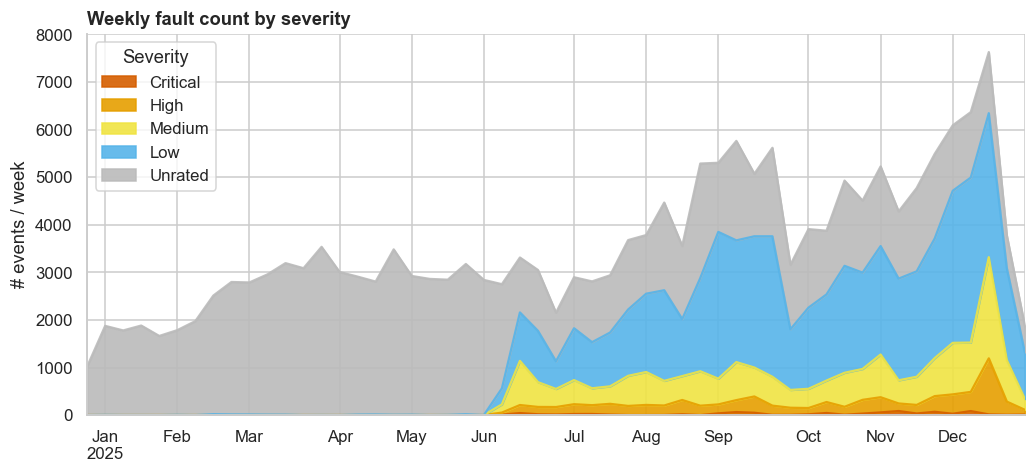

In [129]:
weekly_sev = (
    faults
    .assign(week=lambda d: d["DATE_TIME"].dt.to_period("W").dt.start_time)
    .groupby(["week", "FAULT_SEVERITY_FILLED"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["Critical", "High", "Medium", "Low", "Unrated"], fill_value=0)
)

fig, ax = plt.subplots(figsize=(11, 4.5))
weekly_sev.plot.area(
    ax=ax,
    color=[PALETTE[1], PALETTE[6], PALETTE[4], PALETTE[5], "#BBBBBB"],
    alpha=0.9,
)
ax.set_title("Weekly fault count by severity")
ax.set_ylabel("# events / week")
ax.set_xlabel("")
ax.legend(title="Severity", loc="upper left")
save_fig(fig, "08_faults_weekly_by_severity")
plt.show()

## Job History

### Opens vs completions over time

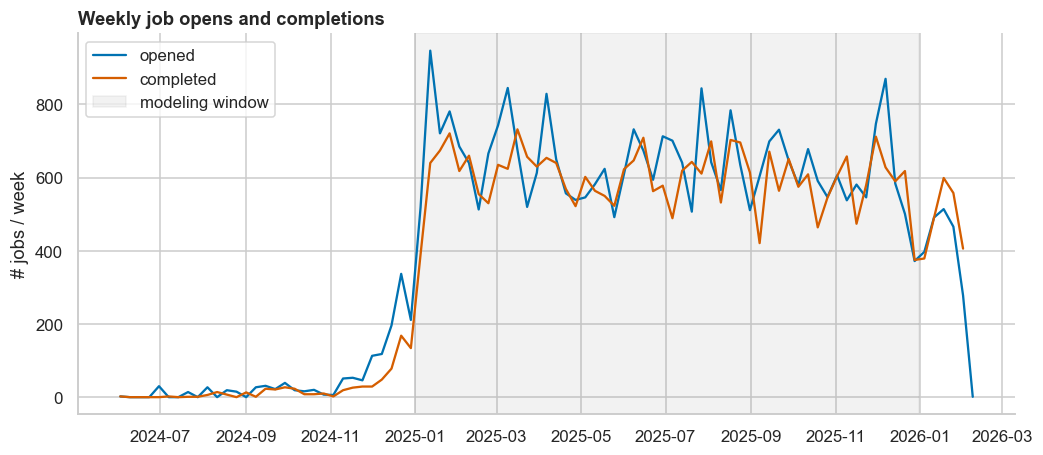

In [130]:
opens_weekly = jobs.set_index("JOB_OPEN_DT").resample("W")["VEHICLE"].count()
closes_weekly = (
    jobs.dropna(subset=["JOB_COMPLETED_DT"])
        .set_index("JOB_COMPLETED_DT")
        .resample("W")["VEHICLE"].count()
)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(opens_weekly.index, opens_weekly.values, label="opened", color=PALETTE[0])
ax.plot(closes_weekly.index, closes_weekly.values, label="completed", color=PALETTE[1])
ax.axvspan(pd.Timestamp(MODEL_START_DATE), pd.Timestamp(MODEL_END_DATE), color="grey", alpha=0.1, label="modeling window")
ax.set_title("Weekly job opens and completions")
ax.set_ylabel("# jobs / week")
ax.legend()
save_fig(fig, "09_jobs_weekly")
plt.show()

### Scheduled vs unscheduled

This is the most important EDA step because it operationally defines the prediction target.
Every `JOB_REASON` code is mapped against the three sets configured in `config.py`:
`UNSCHEDULED_REASONS` (counted as positives), `SCHEDULED_REASONS` (preventive, capital,
recall, and so on), and `EXCLUDED_REASONS` (administrative or external work that we don't
want in either bucket).

In [131]:
classified = dc.classify_jobs(jobs)

reason_summary = (
    classified.groupby(["JOB_REASON", "JOB_REASON_DESC", "SCHEDULE_CLASS"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)
reason_summary

,JOB_REASON,JOB_REASON_DESC,SCHEDULE_CLASS,count
13,P,PREVENTIVE MAINT,scheduled,12375
3,D,DRIVERS REPORT,unscheduled,9797
0,A,DEFECTIVE/ADDITIONAL,unscheduled,8647
1,B,SERV.CALL/BREAKDOWN,unscheduled,2873
5,F,NEGLIGENCE,unscheduled,731
7,H,MODIFICATION,excluded,599
18,U,VERIFY VENDOR WORK,excluded,465
4,E,PARTS SUPPLY,excluded,267
8,J,PREP. FOR DELIVERY,scheduled,255
2,C,CAPITAL IMPROVEMENT,scheduled,235


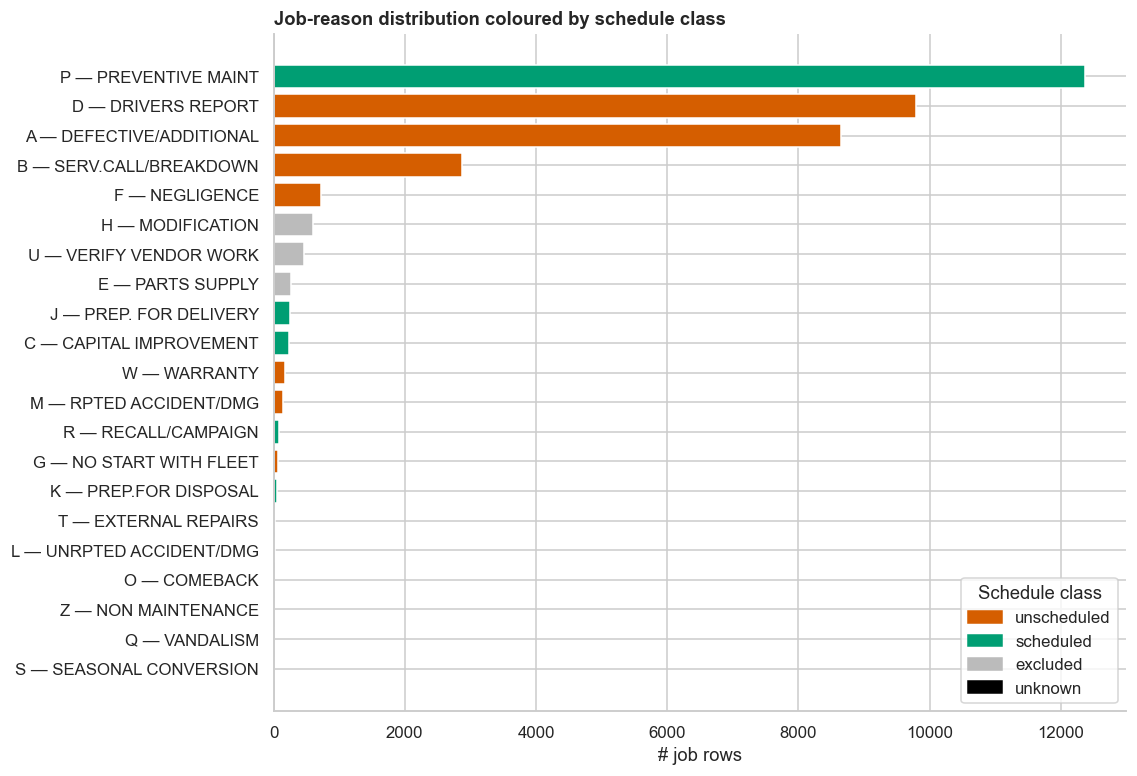

In [132]:
class_colors = {
    "unscheduled": PALETTE[1],
    "scheduled":   PALETTE[2],
    "excluded":    "#BBBBBB",
    "unknown":     "#000000",
}

plot_df = (
    reason_summary.assign(label=lambda d: d["JOB_REASON"] + " — " + d["JOB_REASON_DESC"])
    .sort_values("count", ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 8))
bar_colors = plot_df["SCHEDULE_CLASS"].map(class_colors)
ax.barh(plot_df["label"], plot_df["count"], color=bar_colors)

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in class_colors.values()]
ax.legend(handles, list(class_colors.keys()), title="Schedule class", loc="lower right")
ax.set_title("Job-reason distribution coloured by schedule class")
ax.set_xlabel("# job rows")
save_fig(fig, "10_jobs_reason_class")
plt.show()

### Work order grain

In [133]:
wo = dc.workorder_events(jobs)
print(f"# job rows: {len(jobs):,}")
print(f"# work orders: {len(wo):,}")
print()
print("Schedule class at the work-order grain:")
print(wo["SCHEDULE_CLASS"].value_counts().to_string())

# job rows: 36,829
# work orders: 12,823

Schedule class at the work-order grain:
SCHEDULE_CLASS
unscheduled    10511
scheduled       2166
excluded         146


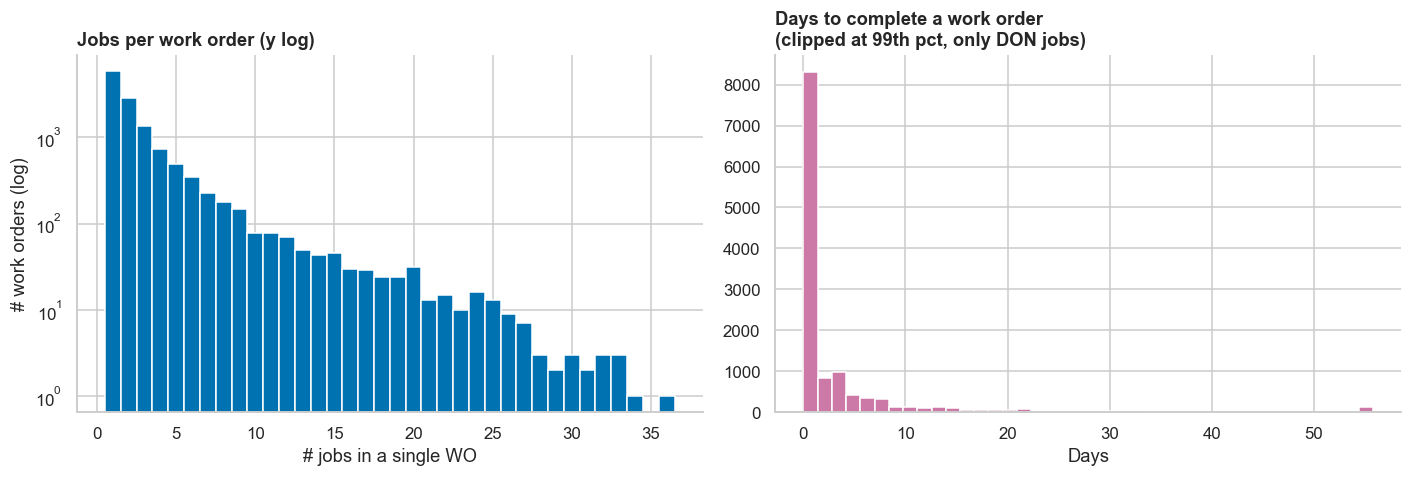

In [134]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

jobs_per_wo = wo["n_jobs"]
axes[0].hist(jobs_per_wo, bins=np.arange(0.5, jobs_per_wo.max() + 1.5), color=PALETTE[0])
axes[0].set_yscale("log")
axes[0].set_title("Jobs per work order (y log)")
axes[0].set_xlabel("# jobs in a single WO")
axes[0].set_ylabel("# work orders (log)")

durations = (wo["JOB_COMPLETED_DT"] - wo["JOB_OPEN_DT"]).dt.total_seconds() / 86400.0
durations = durations.dropna().clip(lower=0)
axes[1].hist(durations.clip(upper=durations.quantile(0.99)), bins=40, color=PALETTE[3])
axes[1].set_title("Days to complete a work order\n(clipped at 99th pct, only DON jobs)")
axes[1].set_xlabel("Days")

fig.tight_layout()
save_fig(fig, "11_jobs_wo_distributions")
plt.show()

### Most common job descriptions

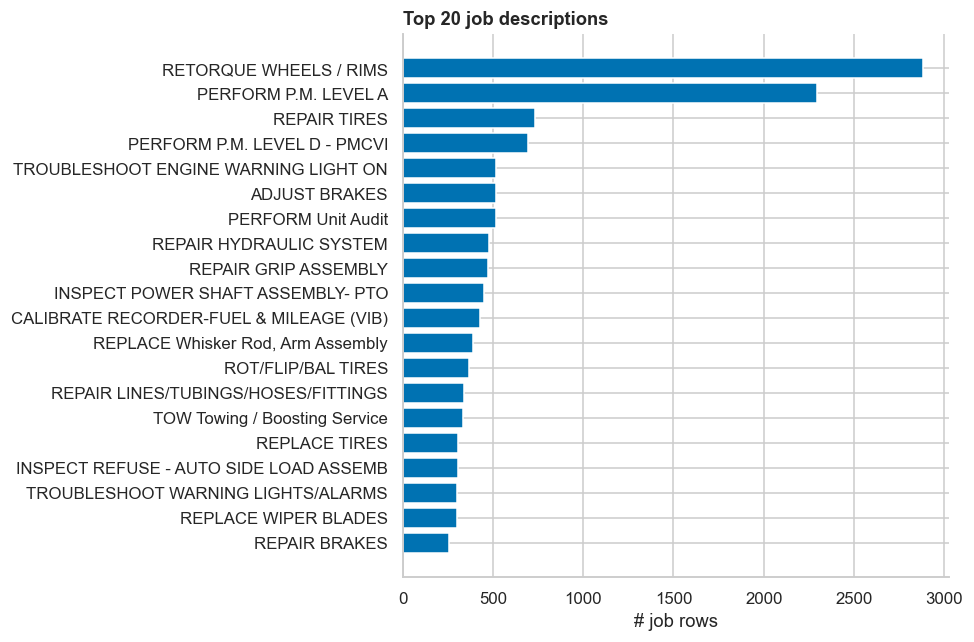

In [135]:
top_desc = jobs["JOB_DESC"].value_counts().head(20)
fig = horizontal_bar(top_desc, title="Top 20 job descriptions", xlabel="# job rows", top_n=None)
save_fig(fig, "12_jobs_top_descriptions")
plt.show()

## Cross-dataset views

### Per-vehicle timeline

For one representative vehicle, chosen as the one with the most varied activity across the
three datasets, plot a stacked timeline of faults (top track, coloured by severity), driving
events (middle track), and unscheduled jobs (bottom track in red). Scheduled jobs are drawn
as background bands. This is where intuition about feature engineering comes from: do faults
cluster before unscheduled repairs? How long are scheduled-maintenance bands?

In [136]:
common_vehicles = sets["driving_events"] & sets["faults"] & sets["jobs"]

activity = pd.DataFrame({
    "drives":   pd.Series({v: (drives["VEHICLE"] == v).sum() for v in common_vehicles}),
    "faults":   pd.Series({v: (faults["VEHICLE"] == v).sum() for v in common_vehicles}),
    "wo":       pd.Series({v: (wo["VEHICLE"] == v).sum()     for v in common_vehicles}),
})
activity["score"] = (
    activity.rank(pct=True).sum(axis=1)
)
sample_vehicle = activity["score"].idxmax()
print(f"Sample vehicle (most varied activity): {sample_vehicle}")
activity.loc[[sample_vehicle]]

Sample vehicle (most varied activity): 161030


,drives,faults,wo,score
161030,107,11014,17,2.858247


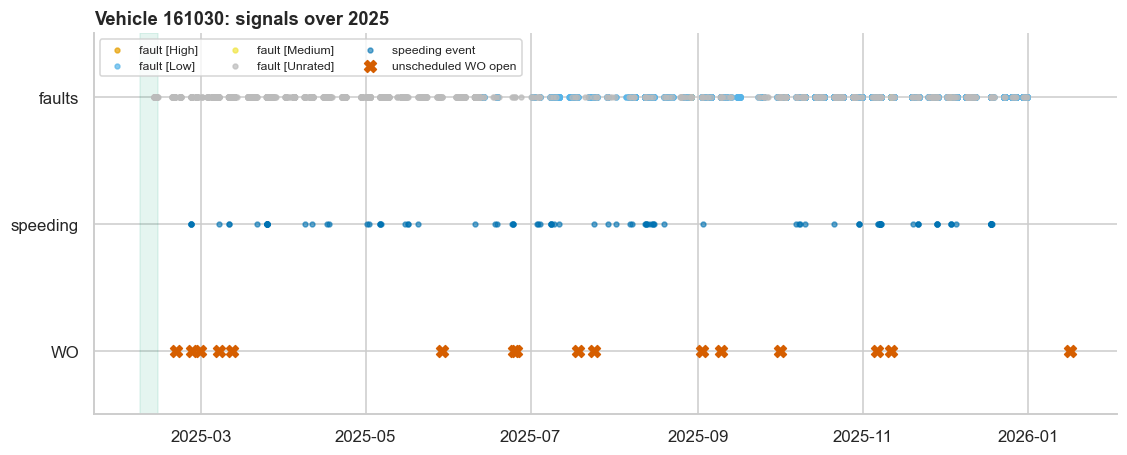

In [137]:
v = sample_vehicle
v_drives = drives.loc[drives["VEHICLE"] == v]
v_faults = faults.loc[faults["VEHICLE"] == v]
v_wo = wo.loc[wo["VEHICLE"] == v]

sev_color = {
    "Critical": PALETTE[1], "High": PALETTE[6], "Medium": PALETTE[4],
    "Low": PALETTE[5], "Unrated": "#BBBBBB",
}

fig, ax = plt.subplots(figsize=(12, 4.5))

# Background bands for scheduled work-orders.
for _, row in v_wo[v_wo["SCHEDULE_CLASS"] == "scheduled"].iterrows():
    end = row["JOB_COMPLETED_DT"] if pd.notna(row["JOB_COMPLETED_DT"]) else row["JOB_OPEN_DT"]
    ax.axvspan(row["JOB_OPEN_DT"], end, color=PALETTE[2], alpha=0.10)

# Track 1 — faults
for sev, group in v_faults.groupby("FAULT_SEVERITY_FILLED"):
    ax.scatter(group["DATE_TIME"], np.full(len(group), 3), s=10,
               color=sev_color.get(sev, "#888"), label=f"fault [{sev}]", alpha=0.7)

# Track 2 — driving events
ax.scatter(v_drives["DATETIME_START"], np.full(len(v_drives), 2), s=10,
           color=PALETTE[0], label="speeding event", alpha=0.6)

# Track 3 — unscheduled work orders
unsched = v_wo[v_wo["SCHEDULE_CLASS"] == "unscheduled"]
ax.scatter(unsched["JOB_OPEN_DT"], np.full(len(unsched), 1), s=60,
           marker="X", color=PALETTE[1], label="unscheduled WO open")

ax.set_yticks([1, 2, 3])
ax.set_yticklabels(["WO", "speeding", "faults"])
ax.set_ylim(0.5, 3.5)
ax.set_title(f"Vehicle {v}: signals over 2025")
handles, labels = ax.get_legend_handles_labels()
seen = set()
unique = [(h, l) for h, l in zip(handles, labels) if not (l in seen or seen.add(l))]
ax.legend([h for h, _ in unique], [l for _, l in unique], loc="upper left", ncol=3, fontsize=8)
save_fig(fig, "13_sample_vehicle_timeline")
plt.show()

### Per-vehicle fault count vs unscheduled WO count

A scatter at the vehicle grain. The third dimension (number of speeding events) is encoded
as point colour. If high-fault vehicles also have many unscheduled repairs, faults will be a
strong feature. If speeding-heavy vehicles cluster in a particular corner, that suggests
driving behaviour matters too.

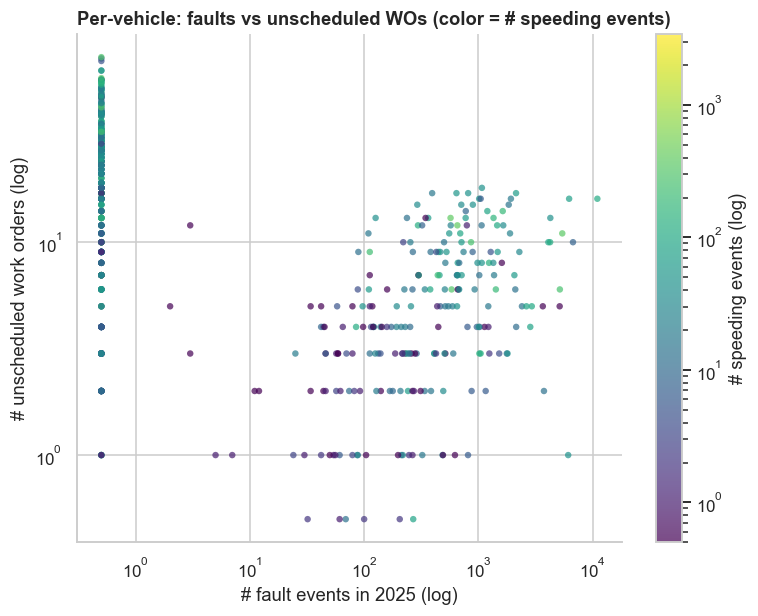

In [138]:
per_v = pd.DataFrame({
    "fault_count":    faults.groupby("VEHICLE").size(),
    "drive_count":    drives.groupby("VEHICLE").size(),
    "unsched_wo_count": wo[wo["SCHEDULE_CLASS"] == "unscheduled"].groupby("VEHICLE").size(),
}).fillna(0).astype(int)

# Keep vehicles present in at least two datasets so the scatter is meaningful.
per_v = per_v[(per_v[["fault_count", "drive_count", "unsched_wo_count"]] > 0).sum(axis=1) >= 2]

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(
    per_v["fault_count"].clip(lower=0.5),
    per_v["unsched_wo_count"].clip(lower=0.5),
    c=per_v["drive_count"].clip(lower=0.5),
    cmap="viridis",
    norm="log",
    s=18,
    alpha=0.7,
    edgecolors="none",
)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("# fault events in 2025 (log)")
ax.set_ylabel("# unscheduled work orders (log)")
ax.set_title("Per-vehicle: faults vs unscheduled WOs (color = # speeding events)")
fig.colorbar(sc, ax=ax, label="# speeding events (log)")
save_fig(fig, "14_per_vehicle_scatter")
plt.show()

### Fleet-wide weekly signals

The three signals on a common time axis. Useful for spotting seasonal patterns and for
confirming the datasets are time-aligned (aside from the wider Job History window).

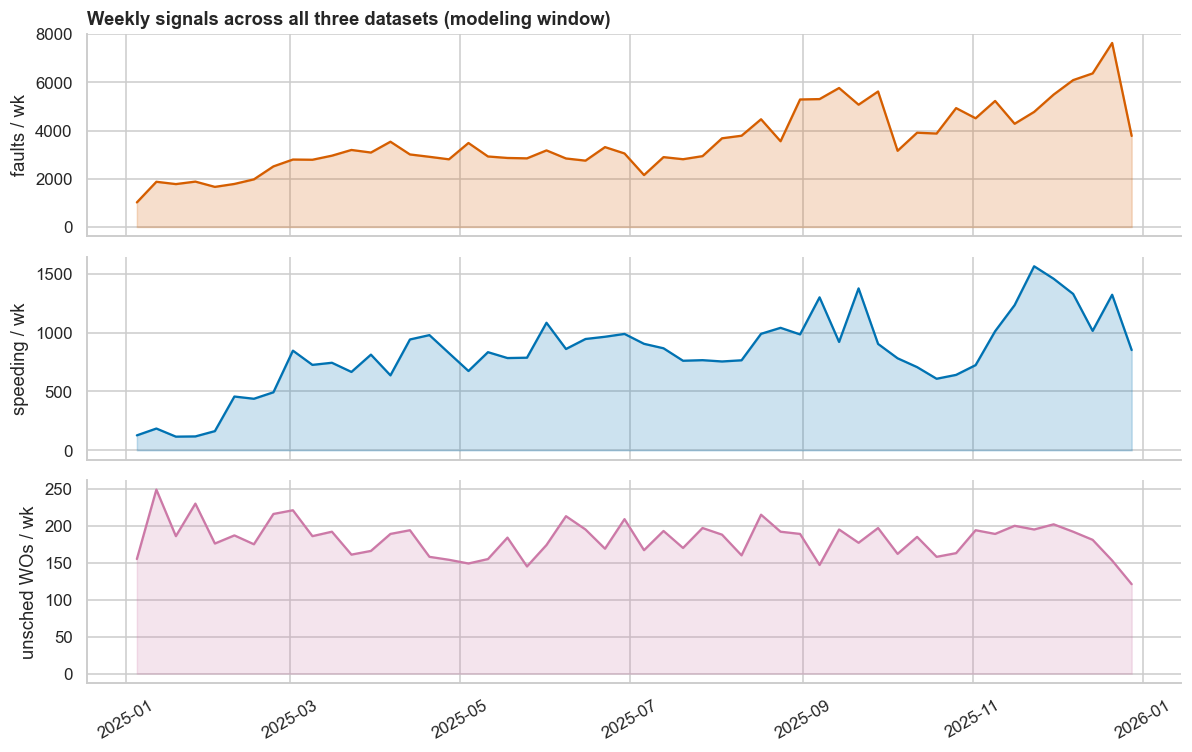

In [139]:
series = pd.DataFrame({
    "faults / wk":     faults.set_index("DATE_TIME").resample("W").size(),
    "speeding / wk":   drives.set_index("DATETIME_START").resample("W").size(),
    "unsched WOs / wk": (
        wo[wo["SCHEDULE_CLASS"] == "unscheduled"]
        .set_index("JOB_OPEN_DT").resample("W").size()
    ),
})
# Restrict to the modeling window so the (wider) job history doesn't dominate.
series = series.loc[MODEL_START_DATE:MODEL_END_DATE]

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, col, color in zip(axes, series.columns, [PALETTE[1], PALETTE[0], PALETTE[3]]):
    ax.plot(series.index, series[col], color=color)
    ax.fill_between(series.index, series[col], alpha=0.2, color=color)
    ax.set_ylabel(col)
axes[-1].tick_params(axis="x", rotation=30)
axes[0].set_title("Weekly signals across all three datasets (modeling window)")
fig.tight_layout()
save_fig(fig, "15_fleet_weekly_signals")
plt.show()

## Key findings and next steps

A few things from this EDA that shaped the modelling stage:

The three files store `VEHICLE` with different dtypes, so any cross-dataset join is silently
broken without explicit normalisation. Only 194 vehicles appear in all three datasets and
that's the modelable cohort — about 400 more sit in Drives and Jobs without any fault
telemetry. `UNIT_TYPE` is 100% HEAVY DUTY and gives nothing to stratify on.

`JOB_REASON` carries the labels. Under the mapping I use, about 82% of work orders are
unscheduled at the WO grain, dominated by driver reports. A WO is treated as unscheduled if
any of its line items is unscheduled; a sensitivity analysis on edge cases like warranty (W)
and recall (R) is worth doing but I leave it for later.

Severity tagging is bimodal in time. Before about June 2025 essentially every fault is
`Unrated`, after which the enriched severity feed starts populating. Severity-based features
are only useful for the second half of 2025, so earlier CV folds have to lean on description
and source instead.

Fault and speeding volumes trend strongly upward over the year while unscheduled WO opens
stay flat. That's likely the telematics fleet expanding mid-year rather than per-vehicle
activity rising. Raw fleet-wide rolling counts aren't directly comparable across the year
because of it, so the model features are built per-vehicle.

`FAILURE_MODE = "0"` (54k rows) is a sentinel for telematics-device-internal events, not a
real value, and the loader treats it as NaN. Fault description and DTC code are nearly but
not perfectly one-to-one. `speed_over_limit_kmh` can be slightly negative when the
truck-specific limit is lower than the posted one; those rows are kept and flagged.

The next step is to fetch Toronto weather and Ontario statutory holidays, build a
per-(vehicle, day) feature matrix with rolling counts and lifetime per-vehicle priors, then
evaluate a gradient-boosted classifier with walk-forward CV against a per-vehicle frequency
baseline.